# Did Oklahoma's earthquakes stop?

**Summary.**

1. The boom is over, but the quakes didn't stop. M2.5+ events fell from 2,990 in 2015 to about 56 in 2025 on a consistent magnitude scale (−98%), still about 14 times the 2000–2008 average.
2. The published 2025 count (30) understates it. Since 2019 the Oklahoma Geological Survey sets most magnitudes, and by 2025 it reads 0.18 lower than USGS for the same quake. On one scale, the rate has been flat since 2023.
3. Most of the boom was aftershocks (93% in 2015). Independent quakes peaked in 2017, two years after the raw count, and are now 6–10 times their pre-2009 rate.
4. The activity moved north to the Kansas border in 2014–2018 and has mostly come back to central Oklahoma. In Stillwater, felt quakes went from one every two days (2014–2016) to 8 in six years.
5. Large quakes fell about as fast as small ones: M4+ from 23 a year at the peak to 1.3 since 2020. They still happen (M5.06 near Prague, February 2024).
6. The rise and fall follow Arbuckle disposal volumes in time and place, with mainshocks peaking three years after injection did; injection into other formations shows no such pattern. Mechanism is cited, not tested.

Open: the size of the OGS–USGS offset at M3+; 2025 injection is the latest year published; the 2024 OCC file is missing locations for about 1,700 wells.

**Goal.** Oklahoma went from a few felt earthquakes a decade to the most seismically active state in the lower 48 around 2015, an increase tied to wastewater injection. The common story is that the quakes "stopped" once regulators cut injection volumes in 2015–2016. Check that against the USGS catalog.

9 Nov 2026 · Thomas with Claude · kernel cdp-node (cdp-kernel 0.8.0, Node 22.23) · package versions pinned in the imports

Data fetched 9 Nov 2026: USGS ComCat (rows are revised over time, so a later fetch can differ slightly) and OCC Form 1012 injection volumes, 2011–2025.

Area: 33.6–37.5° N, 100–94.4° W (Oklahoma and the Kansas border). Events of magnitude 2.5 and up, January 2000 to October 2026.

Recorded: ran in the shell, not in this kernel.

```sh
$ curl -sSfo data/ok-m25.csv "https://earthquake.usgs.gov/fdsnws/event/1/query?format=csv&starttime=2000-01-01&endtime=2026-11-01&minlatitude=33.6&maxlatitude=37.5&minlongitude=-100&maxlongitude=-94.4&minmagnitude=2.5&orderby=time-asc" && wc -l data/ok-m25.csv && head -2 data/ok-m25.csv
```

```text
10189 data/ok-m25.csv
time,latitude,longitude,depth,mag,magType,nst,gap,dmin,rms,net,id,updated,place,type,horizontalError,depthError,magError,magNst,status,locationSource,magSource
2000-10-08T10:16:23.780Z,35.393,-97.98,5,2.6,mblg,7,,,0.38,us,usp000a1f3,2014-11-07T01:11:15.259Z,"3 km W of Union City, Oklahoma",earthquake,,,,,reviewed,us,us
```


## 1. Earthquakes per year

The raw count first: every event of magnitude 2.5 and up in the area, by year. Later sections test whether this count means the same thing in every year.

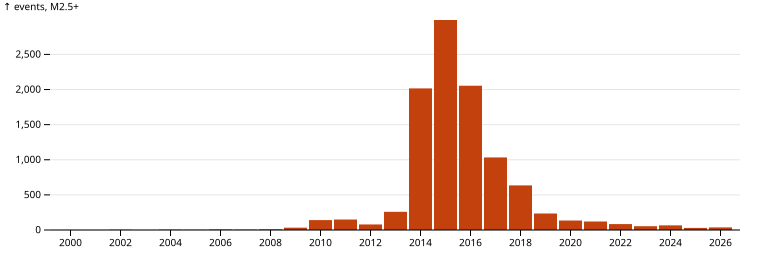

In [1]:
import * as pl from "npm:nodejs-polars@0.18.0";
import * as Plot from "npm:@observablehq/plot@0.6.17";
import { parseHTML } from "npm:linkedom@0.18.9";
import { catalog, md } from "./quakes.ts";

const { document } = parseHTML("<html></html>");
const raw = catalog();
const counts = Object.fromEntries(raw.groupBy("year").agg(pl.col("id").count().alias("n")).toRecords().map((r) => [r.year, r.n]));
// Every year, including ones with no events (2001), so the axis is even.
const perYear = Array.from({ length: 27 }, (_, i) => ({ year: 2000 + i, events: counts[2000 + i] ?? 0 }));

Plot.plot({
  document, width: 760, height: 260, marginLeft: 50,
  x: { label: null, tickFormat: "d", ticks: perYear.filter((d) => d.year % 2 === 0).map((d) => d.year) },
  y: { grid: true, label: "events, M2.5+" },
  marks: [Plot.barY(perYear, { x: "year", y: "events", fill: "#c2410c" }), Plot.ruleY([0])],
})

In [2]:
const peak = perYear.reduce((a, b) => (b.events > a.events ? b : a));
const at = (y: number) => perYear.find((d) => d.year === y)!.events;
jupyter.md`| | events |
|---|---|
| 2000–2008, per year | ${(perYear.filter((d) => d.year <= 2008).reduce((s, d) => s + d.events, 0) / 9).toFixed(1)} |
| peak (${peak.year}) | ${peak.events.toLocaleString()} |
| 2024 | ${at(2024)} |
| 2025 | ${at(2025)} |
| 2026 (Jan–Oct) | ${at(2026)} |
| 2025 vs peak | ${((at(2025) / peak.events - 1) * 100).toFixed(1)}% |`

| | events |
|---|---|
| 2000–2008, per year | 4.1 |
| peak (2015) | 2,990 |
| 2024 | 66 |
| 2025 | 30 |
| 2026 (Jan–Oct) | 37 |
| 2025 vs peak | -99.0% |

**Finding (revised after section 3).** The boom is over: 2,990 events of M2.5+ in 2015, about 56 in 2025 on a consistent magnitude scale (−98%). The published count of 30, which made 2025 look like the quietest year since 2009, is partly a change of network (section 3); on one scale the rate has been flat since 2023. It is not back to before the boom: 2000–2008 averaged 4.1 a year, so 2025 is still about 14 times that.

## 2. Is every year measured the same way?

The catalog merges solutions from several networks, each with its own magnitude scale. If the network or the scale changed over the years, the yearly counts compare different things. Two columns say: `net` (who located the event and set the preferred magnitude) and `magType` (the scale). Also check `type`, since the catalog holds more than earthquakes.

In [3]:
const byYear = (col: string) =>
  raw.groupBy(["year", col]).agg(pl.col("id").count().alias("n"))
     .pivot("n", { index: "year", on: col }).fillNull("zero").sort("year");
// Pivot columns come out in hash order; fix it so the table is the same on every run.
const sorted = (df: pl.DataFrame) => df.select("year", ...df.columns.filter((c) => c !== "year").sort());

md(byYear("net").filter(pl.col("year").gtEq(2012)))

| year | us | ok | ismpkansas |
| --- | --- | --- | --- |
| 2012 | 79 | 0 | 0 |
| 2013 | 259 | 0 | 0 |
| 2014 | 1,985 | 0 | 31 |
| 2015 | 2,946 | 0 | 44 |
| 2016 | 2,054 | 0 | 0 |
| 2017 | 1,033 | 0 | 0 |
| 2018 | 635 | 0 | 0 |
| 2019 | 91 | 144 | 0 |
| 2020 | 7 | 128 | 0 |
| 2021 | 6 | 115 | 0 |
| 2022 | 6 | 78 | 0 |
| 2023 | 1 | 53 | 0 |
| 2024 | 1 | 65 | 0 |
| 2025 | 4 | 26 | 0 |
| 2026 | 1 | 36 | 0 |

In [4]:
md(sorted(byYear("magType")).filter(pl.col("year").gtEq(2008)))

| year | mb | mb_lg | mblg | md | ml | mwc | mwr | mww |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 2008 | 0 | 0 | 5 | 5 | 0 | 0 | 0 | 0 |
| 2009 | 0 | 0 | 33 | 0 | 0 | 0 | 0 | 0 |
| 2010 | 0 | 0 | 53 | 76 | 0 | 1 | 11 | 0 |
| 2011 | 0 | 0 | 17 | 57 | 64 | 0 | 10 | 1 |
| 2012 | 1 | 0 | 9 | 0 | 67 | 0 | 2 | 0 |
| 2013 | 0 | 10 | 12 | 0 | 227 | 0 | 10 | 0 |
| 2014 | 0 | 117 | 0 | 0 | 1,767 | 0 | 131 | 1 |
| 2015 | 2 | 202 | 0 | 0 | 2,619 | 0 | 167 | 0 |
| 2016 | 3 | 84 | 0 | 0 | 1,862 | 0 | 101 | 4 |
| 2017 | 0 | 131 | 0 | 0 | 857 | 0 | 45 | 0 |
| 2018 | 1 | 60 | 0 | 0 | 546 | 0 | 26 | 2 |
| 2019 | 0 | 75 | 0 | 0 | 147 | 0 | 13 | 0 |
| 2020 | 0 | 6 | 0 | 0 | 126 | 0 | 3 | 0 |
| 2021 | 0 | 5 | 0 | 0 | 112 | 0 | 4 | 0 |
| 2022 | 0 | 5 | 0 | 0 | 78 | 0 | 0 | 1 |
| 2023 | 0 | 1 | 0 | 0 | 52 | 0 | 1 | 0 |
| 2024 | 0 | 0 | 0 | 0 | 62 | 0 | 3 | 1 |
| 2025 | 0 | 4 | 0 | 0 | 26 | 0 | 0 | 0 |
| 2026 | 0 | 1 | 0 | 0 | 35 | 0 | 1 | 0 |

In [5]:
// Earthquakes only, from here on.
const quakes = raw.filter(pl.col("type").eq(pl.lit("earthquake")));
md(raw.filter(pl.col("type").neq(pl.lit("earthquake"))).select("time", "mag", "type", "place"), 2)

| time | mag | type | place |
| --- | --- | --- | --- |
| 2020-01-11T13:00:56.700Z | 2.82 | other event | 13 km WNW of Wilson, Oklahoma |
| 2022-07-20T16:43:10.470Z | 2.51 | quarry blast | 9 km WSW of Lebanon, Oklahoma |

**Finding.** The rows are not measured the same way across the years.

- **Who sets the magnitude changed in 2019.** Through 2018 almost every preferred solution is USGS's (`us`). From 2019 it is the Oklahoma Geological Survey's (`ok`): 144 of 235 events that year, and 26 of 30 in 2025.
- **Both use local magnitude (`ml`)**, but each network computes it from its own stations and calibration. The same label does not guarantee the same number for the same quake. These rows alone can't say whether the two agree.
- `mblg` and `mb_lg` are one scale spelled two ways (the spelling changes in 2013); not a real change.
- Two rows are not earthquakes (a quarry blast in 2022, an "other event" in 2020). Dropped from here on as `quakes`.

So the drop after 2019 mixes a real change with a change of network. The size of the second is still unknown.

Recorded: ran in the shell, not in this kernel.

```sh
$ Q="format=csv&starttime=2019-01-01&endtime=2026-11-01&minlatitude=33.6&maxlatitude=37.5&minlongitude=-100&maxlongitude=-94.4&minmagnitude=1.5&orderby=time-asc"; for net in us ok; do curl -sSfo data/$net-m15.csv "https://earthquake.usgs.gov/fdsnws/event/1/query?$Q&catalog=$net"; done; wc -l data/us-m15.csv data/ok-m15.csv
```

```text
   1884 data/us-m15.csv
   9144 data/ok-m15.csv
  11028 total
```


## 3. Do USGS and OGS give the same quake the same magnitude?

ComCat keeps each network's own solution, not only the preferred one. Both catalogs from 2019 on, down to M1.5 so events near the 2.5 cut still find their partner (recorded above). An event in both is the same quake when the origin times are within 8 seconds and the epicentres within 15 km. The difference that matters is USGS minus OGS for the same quake: positive means OGS reads lower.

In [6]:
import { match } from "./quakes.ts";

const usCat = catalog("../data/us-m15.csv").filter(pl.col("type").eq(pl.lit("earthquake")));
const okCat = catalog("../data/ok-m15.csv").filter(pl.col("type").eq(pl.lit("earthquake")));
const pairs = pl.DataFrame(match(usCat.toRecords(), okCat.toRecords()))
  .withColumns(pl.col("magA").minus(pl.col("magB")).alias("diff"));

[usCat.height, okCat.height, pairs.height]

[ 1881, 8353, 1566 ]

In [7]:
const offset = pairs.groupBy("year").agg(
  pl.col("diff").count().alias("pairs"),
  pl.col("diff").quantile(0.25).alias("q25"),
  pl.col("diff").median().alias("median"),
  pl.col("diff").quantile(0.75).alias("q75"),
).sort("year");
md(offset, 2)

| year | pairs | q25 | median | q75 |
| --- | --- | --- | --- | --- |
| 2019 | 293.00 | -0.23 | -0.09 | 0.06 |
| 2020 | 266.00 | -0.16 | -0.05 | 0.10 |
| 2021 | 250.00 | -0.13 | 0.01 | 0.19 |
| 2022 | 183.00 | -0.07 | 0.06 | 0.19 |
| 2023 | 169.00 | -0.04 | 0.12 | 0.24 |
| 2024 | 170.00 | -0.11 | 0.04 | 0.19 |
| 2025 | 137.00 | 0.05 | 0.18 | 0.32 |
| 2026 | 98.00 | 0.04 | 0.18 | 0.30 |

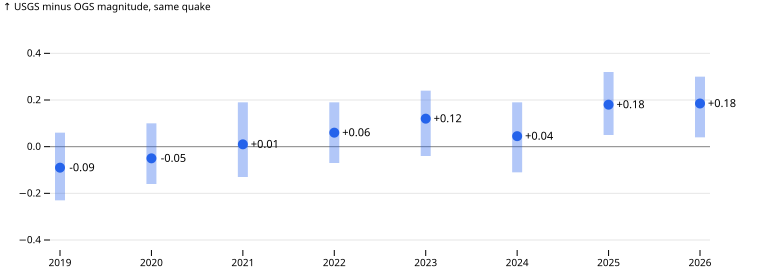

In [8]:
Plot.plot({
  document, width: 760, height: 280, marginLeft: 50, marginRight: 50, inset: 10,
  x: { label: null, tickFormat: "d", ticks: offset.getColumn("year").toArray() },
  y: { grid: true, label: "USGS minus OGS magnitude, same quake", domain: [-0.4, 0.5] },
  marks: [
    Plot.ruleY([0], { stroke: "#888" }),
    Plot.ruleX(offset.toRecords(), { x: "year", y1: "q25", y2: "q75", stroke: "#2563eb", strokeWidth: 10, strokeOpacity: 0.35 }),
    Plot.dot(offset.toRecords(), { x: "year", y: "median", r: 5, fill: "#2563eb" }),
    Plot.text(offset.toRecords(), { x: "year", y: "median", text: (d) => (d.median >= 0 ? "+" : "") + d.median.toFixed(2), dx: 22, fontSize: 11 }),
  ],
})

In [9]:
// Events of M2.5+ per year as each network measures them, next to the preferred (merged) count.
const m25 = (df: pl.DataFrame, name: string) =>
  df.filter(pl.col("mag").gtEq(2.5)).groupBy("year").agg(pl.col("id").count().alias(name));
const scales = m25(quakes.filter(pl.col("year").gtEq(2019)), "preferred")
  .join(m25(usCat, "usgs"), { on: "year" })
  .join(m25(okCat, "ogs"), { on: "year" })
  .sort("year");
md(scales)

| year | preferred | usgs | ogs |
| --- | --- | --- | --- |
| 2019 | 235 | 227 | 144 |
| 2020 | 134 | 134 | 127 |
| 2021 | 121 | 122 | 115 |
| 2022 | 83 | 93 | 77 |
| 2023 | 54 | 70 | 53 |
| 2024 | 66 | 68 | 65 |
| 2025 | 30 | 56 | 26 |
| 2026 | 37 | 64 | 36 |

In [10]:
// When do OGS solutions start? Events per month in the OGS catalog, 2019.
md(okCat.filter(pl.col("year").eq(2019)).groupBy(pl.col("time").str.slice(0, 7).alias("month")).agg(pl.col("id").count().alias("ogs_events")).sort("month"))

| month | ogs_events |
| --- | --- |
| 2019-03 | 107 |
| 2019-04 | 54 |
| 2019-05 | 14 |
| 2019-06 | 170 |
| 2019-07 | 259 |
| 2019-08 | 201 |
| 2019-09 | 143 |
| 2019-10 | 144 |
| 2019-11 | 164 |
| 2019-12 | 137 |

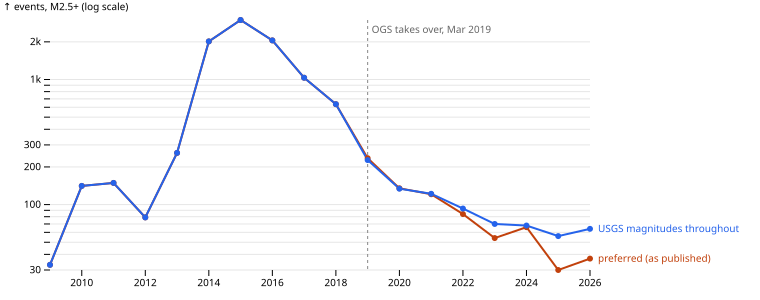

In [11]:
// One series on USGS's own magnitudes for every year: the preferred count through 2018 (all but 75 of those events are USGS's), the USGS catalog from 2019.
const usgsByYear = Object.fromEntries(scales.toRecords().map((r) => [r.year, r.usgs]));
const series = perYear.filter((d) => d.year >= 2009).flatMap((d) => [
  { year: d.year, events: d.events, series: "preferred (as published)" },
  { year: d.year, events: d.year >= 2019 ? usgsByYear[d.year] : d.events, series: "USGS magnitudes throughout" },
]);
Plot.plot({
  document, width: 760, height: 300, marginLeft: 50, marginRight: 170,
  x: { label: null, tickFormat: "d" },
  y: { type: "log", grid: true, label: "events, M2.5+ (log scale)" },
  color: { domain: ["preferred (as published)", "USGS magnitudes throughout"], range: ["#c2410c", "#2563eb"] },
  marks: [
    Plot.ruleX([2019], { stroke: "#888", strokeDasharray: "3,3" }),
    Plot.text([{ x: 2019, y: 2500 }], { x: "x", y: "y", text: () => "OGS takes over, Mar 2019", textAnchor: "start", dx: 4, fill: "#666" }),
    Plot.line(series, { x: "year", y: "events", stroke: "series", strokeWidth: 2 }),
    Plot.dot(series, { x: "year", y: "events", fill: "series", r: 3 }),
    Plot.text(series.filter((d) => d.year === 2026), { x: "year", y: "events", text: "series", fill: "series", textAnchor: "start", dx: 8 }),
  ],
})

**Finding.** OGS has been reading lower than USGS for the same quake, and the gap is growing. In 2019 OGS read 0.09 higher (median of 293 matched quakes); by 2025–2026 it reads 0.18 lower. Near the 2.5 cut, a few tenths of a magnitude decide whether a quake is counted at all.

On USGS's own magnitudes, 2025 had **56** events of M2.5+, not 30, and 2026 has 64 through October, not 37. The published series makes 2025 look like a new low; on one scale the rate has been **flat at about 55–70 a year since 2023**. The steep fall from 2015 to 2021 is real on either scale.

(2019 differs the other way only because OGS solutions start in March 2019.)

## 4. Mainshocks or aftershocks?

A swarm year counts every aftershock. Separate them with the standard Gardner–Knopoff (1974) windows: a quake of magnitude *m* claims smaller quakes within a distance and time that grow with *m* (M3: 22 km, 12 days; M4: 30 km, 41 days; M5.8 Pawnee: 49 km, 391 days). What is left, the mainshocks, is the rate of independent quakes: the background the question is really about. `decluster()` in `quakes.ts`.

In [12]:
import { decluster } from "./quakes.ts";

const dep = decluster(quakes.toRecords());
const labelled = quakes.withColumns(pl.Series("kind", dep.map((d) => (d ? "aftershock" : "mainshock"))));
const kinds = labelled.groupBy("year").agg(
  pl.col("id").count().alias("all"),
  pl.col("kind").eq(pl.lit("mainshock")).sum().alias("mainshocks"),
).withColumns(pl.col("mainshocks").cast(pl.Float64).div(pl.col("all")).mul(100).alias("mainshock_pct")).sort("year");
md(kinds.filter(pl.col("year").gtEq(2009)))

| year | all | mainshocks | mainshock_pct |
| --- | --- | --- | --- |
| 2009 | 33 | 17 | 52 |
| 2010 | 141 | 38 | 27 |
| 2011 | 149 | 22 | 15 |
| 2012 | 79 | 19 | 24 |
| 2013 | 259 | 62 | 24 |
| 2014 | 2,016 | 174 | 9 |
| 2015 | 2,990 | 201 | 7 |
| 2016 | 2,054 | 165 | 8 |
| 2017 | 1,033 | 217 | 21 |
| 2018 | 635 | 207 | 33 |
| 2019 | 235 | 117 | 50 |
| 2020 | 134 | 75 | 56 |
| 2021 | 121 | 64 | 53 |
| 2022 | 83 | 47 | 57 |
| 2023 | 54 | 34 | 63 |
| 2024 | 66 | 34 | 52 |
| 2025 | 30 | 23 | 77 |
| 2026 | 37 | 23 | 62 |

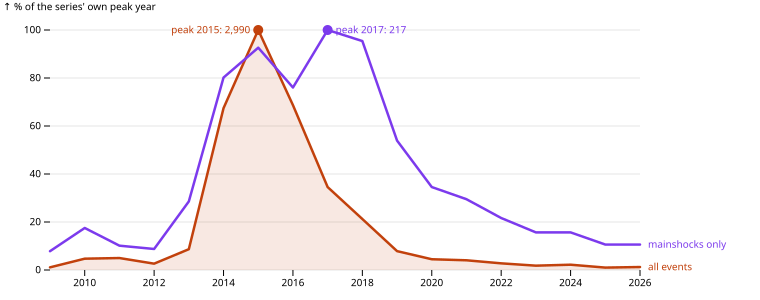

In [13]:
// Each series as a share of its own peak year, so their shapes can be compared.
const k = kinds.filter(pl.col("year").gtEq(2009)).toRecords();
const peakAll = Math.max(...k.map((d) => d.all)), peakMain = Math.max(...k.map((d) => d.mainshocks));
const shapes = k.flatMap((d) => [
  { year: d.year, share: d.all / peakAll, n: d.all, series: "all events" },
  { year: d.year, share: d.mainshocks / peakMain, n: d.mainshocks, series: "mainshocks only" },
]);
Plot.plot({
  document, width: 760, height: 300, marginLeft: 50, marginRight: 120, marginTop: 30,
  x: { label: null, tickFormat: "d" },
  y: { grid: true, percent: true, label: "% of the series' own peak year" },
  color: { domain: ["all events", "mainshocks only"], range: ["#c2410c", "#7c3aed"] },
  marks: [
    Plot.areaY(shapes.filter((d) => d.series === "all events"), { x: "year", y: "share", fill: "#c2410c", fillOpacity: 0.12 }),
    Plot.line(shapes, { x: "year", y: "share", stroke: "series", strokeWidth: 2.5 }),
    Plot.dot(shapes.filter((d) => d.share === 1), { x: "year", y: "share", fill: "series", r: 5 }),
    Plot.text(shapes.filter((d) => d.share === 1 && d.series === "all events"), { x: "year", y: "share", text: (d) => `peak ${d.year}: ${d.n.toLocaleString()}`, dx: -8, textAnchor: "end", fill: "series" }),
    Plot.text(shapes.filter((d) => d.share === 1 && d.series === "mainshocks only"), { x: "year", y: "share", text: (d) => `peak ${d.year}: ${d.n}`, dx: 8, textAnchor: "start", fill: "series" }),
    Plot.text(shapes.filter((d) => d.year === 2026), { x: "year", y: "share", text: "series", fill: "series", textAnchor: "start", dx: 8 }),
  ],
})

In [14]:
// Baseline and recent mainshock rates, for the finding below.
const ks = kinds.toRecords();
jupyter.md`| | mainshocks per year |
|---|---|
| 2000–2008 average | ${(ks.filter((d) => d.year <= 2008).reduce((s, d) => s + d.mainshocks, 0) / 9).toFixed(1)} |
${ks.filter((d) => d.year >= 2023).map((d) => `| ${d.year} | ${d.mainshocks} |`).join("\n")}`

| | mainshocks per year |
|---|---|
| 2000–2008 average | 3.6 |
| 2023 | 34 |
| 2024 | 34 |
| 2025 | 23 |
| 2026 | 23 |

**Finding.** Most of the boom's count was aftershocks, and independent quakes peaked two years later than the count did.

- In 2015, only 201 of 2,990 events (7%) were mainshocks. The rest belonged to sequences.
- **Mainshocks peaked in 2017 (217), not 2015.** The fall in the raw count from 2015 to 2017 (−65%) was fewer aftershocks; independent quakes were still rising, after the 2015–2016 injection cuts had begun.
- From 2017 to 2025 mainshocks fell 89% (217 to 23). Since 2023 they run at 23–34 a year, about 6–10 times the 2000–2008 average of 3.6. These use the published magnitudes, so the recent years are slightly low (section 3).

So the background rate came down, but more slowly than the headline count, and it hasn't gone back to where it was.

## 5. Where are they?

Mainshocks only (section 4), so a single aftershock sequence doesn't paint a region, in four eras: before the boom took off, the peak, the fall, and since. Dot size is magnitude. State lines from the US Census atlas (`us-atlas`).

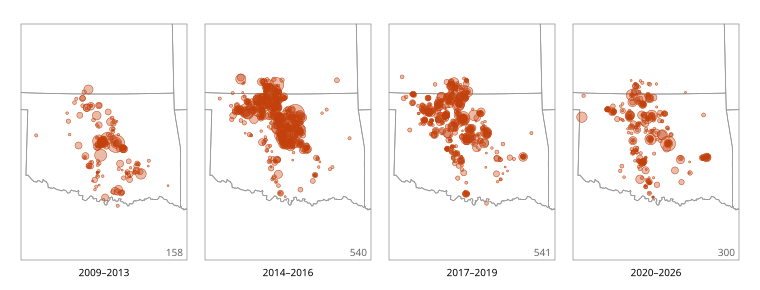

In [15]:
import * as topo from "npm:topojson-client@3.1.0";
import us from "npm:us-atlas@3.0.1/states-10m.json" with { type: "json" };

const states = topo.feature(us, us.objects.states);
const near = { type: "FeatureCollection", features: states.features.filter((f) => ["Oklahoma", "Kansas", "Texas", "Arkansas", "Missouri"].includes(f.properties.name)) };
const box = { type: "MultiPoint", coordinates: [[-100, 33.6], [-94.4, 37.5], [-100, 37.5], [-94.4, 33.6]] };
const era = (y: number) => (y < 2014 ? "2009–2013" : y < 2017 ? "2014–2016" : y < 2020 ? "2017–2019" : "2020–2026");
const mains = labelled.filter(pl.col("kind").eq(pl.lit("mainshock"))).filter(pl.col("year").gtEq(2009))
  .toRecords().map((d) => ({ ...d, era: era(d.year) }));

Plot.plot({
  document, width: 760, height: 290, marginTop: 24,
  projection: { type: "conic-equal-area", parallels: [34, 37], rotate: [97.2, 0], domain: box, inset: 4 },
  fx: { label: null, domain: ["2009–2013", "2014–2016", "2017–2019", "2020–2026"] },
  r: { range: [1, 9], domain: [2.5, 5.8] },
  marks: [
    Plot.geo(near, { stroke: "#999", strokeWidth: 0.8 }),
    Plot.dot(mains, { x: "lon", y: "lat", r: "mag", fx: "era", fill: "#c2410c", fillOpacity: 0.35, stroke: "#c2410c", strokeWidth: 0.5 }),
    Plot.text(mains, Plot.groupZ({ text: "count" }, { fx: "era", frameAnchor: "bottom-right", dy: -4, dx: -4, text: (d) => d, fill: "#666" })),
  ],
})

In [16]:
// How far north: share of mainshocks above 36.5° N (north-central Oklahoma and the Kansas border), by year.
const north = pl.DataFrame(mains).groupBy("year").agg(
  pl.col("id").count().alias("mainshocks"),
  pl.col("lat").mean().alias("mean_lat"),
  pl.col("lat").gtEq(36.5).cast(pl.Float64).mean().mul(100).alias("pct_north_of_36_5"),
).sort("year");
md(north, 1)

| year | mainshocks | mean_lat | pct_north_of_36_5 |
| --- | --- | --- | --- |
| 2009 | 17.0 | 35.5 | 0.0 |
| 2010 | 38.0 | 35.1 | 2.6 |
| 2011 | 22.0 | 35.1 | 0.0 |
| 2012 | 19.0 | 35.4 | 5.3 |
| 2013 | 62.0 | 35.6 | 21.0 |
| 2014 | 174.0 | 36.2 | 39.7 |
| 2015 | 201.0 | 36.3 | 40.8 |
| 2016 | 165.0 | 36.2 | 38.2 |
| 2017 | 217.0 | 36.3 | 35.9 |
| 2018 | 207.0 | 36.2 | 33.3 |
| 2019 | 117.0 | 35.9 | 27.4 |
| 2020 | 75.0 | 36.2 | 32.0 |
| 2021 | 64.0 | 35.8 | 25.0 |
| 2022 | 47.0 | 35.9 | 31.9 |
| 2023 | 34.0 | 35.8 | 17.6 |
| 2024 | 34.0 | 35.8 | 11.8 |
| 2025 | 23.0 | 35.9 | 21.7 |
| 2026 | 23.0 | 35.3 | 0.0 |

**Finding.** The activity did move north and come back, partly.

- Before 2013, almost no mainshocks were north of 36.5° N. From 2014 to 2018, 33–41% were, along the Kansas border (the dense clusters in the 2014–2016 and 2017–2019 maps).
- Since 2023 that share is 12–22% (0 of 23 so far in 2026), and the average latitude is 35.8–35.9°, south of the 36.2–36.3° of 2014–2018 but still north of 2009–2013 (35.1–35.6°).
- What remains is a band from north-central Oklahoma down through the center of the state, overlapping the area of the 2009–2013 activity but reaching further north.

## 6. One town: Stillwater

Thomas added the two cells below: the question, and the town with a 40 km radius. Using them as given: every quake within `town.radiusKm` of the town, and those of M3+, which people in town would usually feel. All events here, aftershocks included, since an aftershock shakes the house just the same.

**Thomas:** what has this been like in one town? Stillwater is between the Pawnee and Cushing quakes. Count quakes within 40 km of town by year, and the ones people would have felt (M3+).

In [17]:
const town = { name: "Stillwater", lat: 36.1156, lon: -97.0584, radiusKm: 40 };

In [18]:
import { km } from "./quakes.ts";

const local = quakes.toRecords()
  .map((d) => ({ ...d, dist: km(town.lat, town.lon, d.lat, d.lon) }))
  .filter((d) => d.dist <= town.radiusKm);
const localYears = Array.from({ length: 2026 - 2009 + 1 }, (_, i) => 2009 + i).map((year) => {
  const ys = local.filter((d) => d.year === year);
  return { year, events: ys.length, felt_m3: ys.filter((d) => d.mag >= 3).length, largest: ys.length ? Math.max(...ys.map((d) => d.mag)).toFixed(1) : "–" };
});
md(pl.DataFrame(localYears))

| year | events | felt_m3 | largest |
| --- | --- | --- | --- |
| 2009 | 2 | 1 | 3.0 |
| 2010 | 2 | 0 | 2.6 |
| 2011 | 2 | 0 | 2.8 |
| 2012 | 4 | 2 | 3.3 |
| 2013 | 20 | 7 | 3.7 |
| 2014 | 631 | 180 | 4.2 |
| 2015 | 649 | 209 | 4.3 |
| 2016 | 464 | 131 | 5.8 |
| 2017 | 154 | 45 | 4.1 |
| 2018 | 55 | 18 | 3.5 |
| 2019 | 12 | 3 | 3.3 |
| 2020 | 20 | 6 | 4.2 |
| 2021 | 6 | 1 | 3.7 |
| 2022 | 1 | 0 | 2.6 |
| 2023 | 13 | 5 | 4.0 |
| 2024 | 4 | 1 | 3.0 |
| 2025 | 4 | 1 | 3.2 |
| 2026 | 2 | 0 | 2.9 |

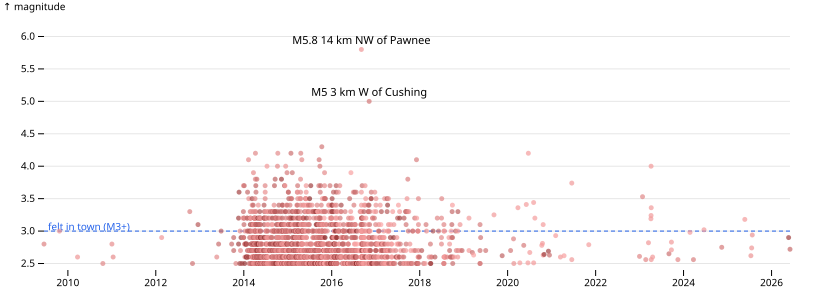

In [19]:
// Every quake within the radius, 2009 on: when, how big, how far from town (darker = closer).
const notable = local.filter((d) => d.mag >= 4.5);
Plot.plot({
  document, width: 820, height: 300, marginLeft: 44, marginRight: 30, marginTop: 30,
  x: { type: "utc", label: null },
  y: { grid: true, label: "magnitude", domain: [2.4, 6.1] },
  color: { type: "linear", domain: [0, 40], range: ["#7f1d1d", "#fca5a5"], legend: false },
  marks: [
    Plot.ruleY([3], { stroke: "#2563eb", strokeDasharray: "4,3" }),
    Plot.text(["felt in town (M3+)"], { frameAnchor: "top-left", y: 3, dy: -8, dx: 4, fill: "#2563eb", textAnchor: "start" }),
    Plot.dot(local.filter((d) => d.year >= 2009), { x: (d) => new Date(d.time), y: "mag", r: 2.5, fill: "dist", fillOpacity: 0.7 }),
    Plot.text(notable, { x: (d) => new Date(d.time), y: "mag", text: (d) => `M${d.mag} ${d.place.replace(/, Oklahoma$/, "")}`, dy: -9, fontSize: 11 }),
  ],
})

In [20]:
// The felt quakes since 2021, for the finding below.
md(pl.DataFrame(local.filter((d) => d.year >= 2021 && d.mag >= 3).map((d) => ({ date: d.time.slice(0, 10), mag: d.mag, place: d.place, km_from_town: d.dist }))), 1)

| date | mag | place | km_from_town |
| --- | --- | --- | --- |
| 2021-06-16 | 3.7 | 3 km SE of Carney, Oklahoma | 36.6 |
| 2023-01-25 | 3.5 | 5 km ENE of Meridian, Oklahoma | 31.7 |
| 2023-04-05 | 3.2 | 4 km ESE of Carney, Oklahoma | 36.6 |
| 2023-04-06 | 4.0 | 4 km ESE of Carney, Oklahoma | 36.7 |
| 2023-04-06 | 3.2 | Oklahoma | 36.7 |
| 2023-04-07 | 3.4 | 3 km ESE of Carney, Oklahoma | 36.8 |
| 2024-06-19 | 3.0 | 11 km E of Red Rock, Oklahoma | 36.7 |
| 2025-05-23 | 3.2 | 11 km NW of Pawnee, Oklahoma | 37.3 |

**Finding.** In Stillwater the boom was a daily experience and is now an occasional one.

- 2014–2016: 1,744 quakes within 40 km, 520 of them M3+: a quake people would feel about every two days for three years, plus the two largest in the record, M5.8 Pawnee (Sep 2016, 37 km away) and M5.0 Cushing (Nov 2016).
- 2021 to October 2026: 8 felt quakes in almost six years, 4 of them in a three-day sequence near Carney in April 2023 (largest M4.0, 37 km away).
- 2009–2012: three felt quakes in four years.

The town is close to its pre-boom experience, though not at it, and on USGS's scale (section 3) the recent counts would be a little higher.

## 7. Are the big ones falling as fast as the count?

Damage comes from the rare large quakes, so the question is whether the share of large ones changed. Two ways to look:

1. **M4+ per year**, next to all events. Few, so read them by era, not by year.
2. **The Gutenberg–Richter slope (*b*-value).** Counts fall about tenfold per magnitude unit; *b* is that slope. A lower *b* means a larger share of big quakes. Maximum-likelihood estimate (Aki 1965) above M2.5, with its standard error *b*/√n. Eras as in section 5.

In [21]:
const eraOf = (y: number) => (y < 2009 ? null : era(y));
const eraStats = ["2009–2013", "2014–2016", "2017–2019", "2020–2026"].map((name) => {
  const m = quakes.toRecords().filter((d) => eraOf(d.year) === name).map((d) => d.mag);
  const mean = m.reduce((s, v) => s + v, 0) / m.length;
  const b = Math.LOG10E / (mean - (2.5 - 0.05));
  return {
    era: name, events: m.length, m4: m.filter((v) => v >= 4).length,
    per_1000: (1000 * m.filter((v) => v >= 4).length) / m.length,
    b, b_se: b / Math.sqrt(m.length),
  };
});
md(pl.DataFrame(eraStats), 2)

| era | events | m4 | per_1000 | b | b_se |
| --- | --- | --- | --- | --- | --- |
| 2009–2013 | 661.00 | 10.00 | 15.13 | 0.93 | 0.04 |
| 2014–2016 | 7,060.00 | 70.00 | 9.92 | 1.07 | 0.01 |
| 2017–2019 | 1,903.00 | 16.00 | 8.41 | 1.16 | 0.03 |
| 2020–2026 | 525.00 | 9.00 | 17.14 | 1.10 | 0.05 |

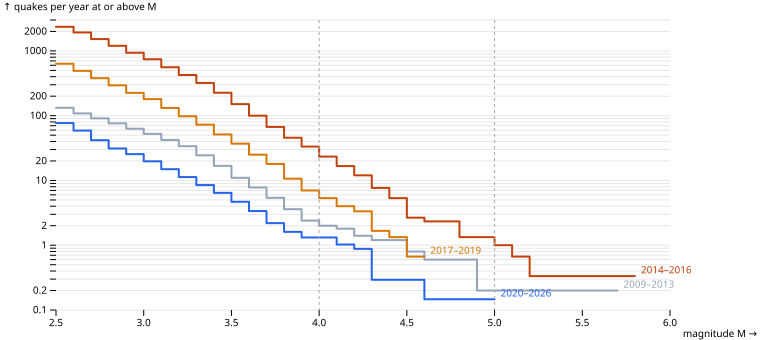

In [22]:
// Gutenberg–Richter: quakes per year at or above each magnitude, one line per era.
const eraYears = { "2009–2013": 5, "2014–2016": 3, "2017–2019": 3, "2020–2026": 6 + 10 / 12 };
const grid = Array.from({ length: 34 }, (_, i) => +(2.5 + i * 0.1).toFixed(1));
const gr = Object.entries(eraYears).flatMap(([name, years]) => {
  const m = quakes.toRecords().filter((d) => eraOf(d.year) === name).map((d) => d.mag);
  return grid.map((M) => ({ era: name, M, perYear: m.filter((v) => v >= M - 1e-9).length / years })).filter((d) => d.perYear > 0);
});
Plot.plot({
  document, width: 760, height: 340, marginLeft: 56, marginRight: 90,
  x: { label: "magnitude M", domain: [2.5, 6] },
  y: { type: "log", grid: true, label: "quakes per year at or above M", tickFormat: "~g", domain: [0.1, 3000] },
  color: { domain: Object.keys(eraYears), range: ["#94a3b8", "#c2410c", "#d97706", "#2563eb"] },
  marks: [
    Plot.line(gr, { x: "M", y: "perYear", stroke: "era", strokeWidth: 2, curve: "step-after" }),
    Plot.text(gr, Plot.selectLast({ x: "M", y: "perYear", z: "era", text: "era", fill: "era", textAnchor: "start", dx: 6, dy: -6 })),
    Plot.ruleX([4, 5], { stroke: "#aaa", strokeDasharray: "3,3" }),
  ],
})

In [23]:
// Every M4.5+ quake, for the finding below.
md(quakes.filter(pl.col("mag").gtEq(4.5)).select(pl.col("time").str.slice(0, 10).alias("date"), "mag", "place").sort("date"), 2)

| date | mag | place |
| --- | --- | --- |
| 2011-11-05 | 4.80 | 8 km SE of Sparks, Oklahoma |
| 2011-11-06 | 5.70 | 8 km NW of Prague, Oklahoma |
| 2011-11-08 | 4.80 | 9 km SSE of Sparks, Oklahoma |
| 2013-12-07 | 4.50 | 8 km SW of Arcadia, Oklahoma |
| 2014-11-12 | 4.90 | 4 km ENE of Milan, Kansas |
| 2015-07-27 | 4.50 | 4 km NNE of Crescent, Oklahoma |
| 2015-11-19 | 4.70 | 4 km SW of Lambert, Oklahoma |
| 2015-11-30 | 4.70 | 8 km E of Nescatunga, Oklahoma |
| 2016-01-07 | 4.70 | 16 km SE of Waynoka, Oklahoma |
| 2016-02-13 | 5.10 | 18 km SE of Waynoka, Oklahoma |
| 2016-09-03 | 5.80 | 14 km NW of Pawnee, Oklahoma |
| 2016-11-07 | 5.00 | 3 km W of Cushing, Oklahoma |
| 2018-04-07 | 4.60 | 5 km WNW of Lucien, Oklahoma |
| 2018-04-09 | 4.60 | 8 km NNE of Marshall, Oklahoma |
| 2022-01-31 | 4.50 | 7 km NW of Medford, Oklahoma |
| 2024-02-03 | 5.06 | 8 km NW of Prague, Oklahoma |

**Finding.** The risk of a large quake fell about as fast as the count: not faster, and not measurably slower.

- The whole curve moved down. The mix of sizes did shift some: *b* rose from 1.07 at the peak to 1.16 in 2017–2019 (fewer large quakes per event as the rate fell) and is 1.10 since 2020, the same as the peak within its error. 2009–2013 had the largest share of big quakes (*b* 0.93). The *b* estimates assume magnitudes rounded to 0.1; OGS reports two decimals, which would lower the 2020–2026 *b* by up to 0.1 (to about 1.0), so the recent mix may hold slightly more large quakes than the peak's. M4+ ran at 23 a year in 2014–2016, 5.3 in 2017–2019 and 1.3 since 2020, below 2009–2013 (2 a year).
- 2020–2026 has more M4+ per 1,000 events (17) than the peak (10), but that is 9 quakes. A Poisson 95% range for 9 is 4 to 17, or 8 to 33 per 1,000, which includes the peak's rate. OGS's lower magnitudes (section 3) also shrink the denominator.
- Pawnee (M5.8, Sep 2016) came when the raw count was falling but mainshocks were still near their peak (section 4). That is the series to watch for large-quake risk, not the headline count.
- Large quakes have not stopped: M5.06 near Prague in February 2024 (table above).

Recorded: ran in the shell, not in this kernel.

```sh
$ mkdir -p data/occ && for y in $(seq 2011 2025); do curl -sSfLo data/occ/$y.xlsx "https://oklahoma.gov/content/dam/ok/en/occ/documents/og/ogdatafiles/$y-uic-injection-volumes.xlsx"; done; ls data/occ | wc -l; du -sh data/occ
```

```text
15
51M	data/occ
```


## 8. Does injection line up with the quakes?

The catalog alone can't show cause. The Oklahoma Corporation Commission publishes every disposal well's monthly injection volume (Form 1012), 2011–2025 (recorded above). Disposal into the deep Arbuckle group, close to the basement faults, is the injection linked to the quakes; the OCC's 2015–2016 directives cut Arbuckle volumes in the quake areas. Wells inside the study area only. This can show whether timing and place line up, not prove cause.

In [24]:
import { injection } from "./quakes.ts";

const inj = (await injection(Array.from({ length: 15 }, (_, i) => 2011 + i)))
  .filter(pl.col("lat").gtEq(33.6).and(pl.col("lat").ltEq(37.5)).and(pl.col("lon").gtEq(-100)).and(pl.col("lon").ltEq(-94.4)));
[inj.height, inj.select(pl.col("api").nUnique()).row(0)[0]]

[ 1284694, 11378 ]

In [25]:
// Sanity check before summing: the largest single well-month volumes.
md(inj.sort("barrels", true).head(8).select("year", "month", "api", "formation", "barrels"))

| year | month | api | formation | barrels |
| --- | --- | --- | --- | --- |
| 2020 | 2 | 3507324320 | OSWEGO | 10,009,670 |
| 2020 | 8 | 3507324320 | OSWEGO | 8,935,046 |
| 2024 | 2 | 3504322287 | LOWER MORROW SAND | 8,300,091 |
| 2020 | 1 | 3513325025 | ARBUCKLE | 5,158,248 |
| 2020 | 12 | 3501520306 | PONTOTOC | 4,876,145 |
| 2018 | 1 | 3513726796 | LOCO SAND|LOCO SD | 4,013,325 |
| 2018 | 2 | 3513726796 | LOCO SAND|LOCO SD | 4,013,325 |
| 2018 | 3 | 3513726796 | LOCO SAND|LOCO SD | 4,013,325 |

In [26]:
// The numbers behind the cut-off below.
const q999 = inj.filter(pl.col("arbuckle")).select(pl.col("barrels").quantile(0.999)).row(0)[0];
jupyter.md`| | |
|---|---|
| well-month rows in the area | ${inj.height.toLocaleString()} |
| Arbuckle well-months, 99.9th percentile | ${Math.round(q999).toLocaleString()} barrels |
| well-months over 2 million barrels | ${inj.filter(pl.col("barrels").gt(2_000_000)).height} |`

| | |
|---|---|
| well-month rows in the area | 1,284,694 |
| Arbuckle well-months, 99.9th percentile | 1,107,043 barrels |
| well-months over 2 million barrels | 43 |

**Data check.** Some reports are not believable: one shallow Oswego well reports 10 million barrels in a month (330,000 a day), and another repeats 4.0 million every month of 2018. The busiest Arbuckle wells top out near 1.1 million a month (99.9th percentile). Well-months over 2 million barrels are dropped as entry errors: 43 of 1.28 million rows.

In [27]:
const injOk = inj.filter(pl.col("barrels").ltEq(2_000_000));
const injYear = injOk.groupBy("year").agg(
  pl.col("barrels").filter(pl.col("arbuckle")).sum().div(1e6).alias("arbuckle_mbbl"),
  pl.col("barrels").filter(pl.col("arbuckle").not()).sum().div(1e6).alias("other_mbbl"),
  pl.col("api").filter(pl.col("arbuckle")).nUnique().alias("arbuckle_wells"),
).sort("year");
md(injYear)

| year | arbuckle_mbbl | other_mbbl | arbuckle_wells |
| --- | --- | --- | --- |
| 2011 | 252 | 1,604 | 290 |
| 2012 | 448 | 1,646 | 424 |
| 2013 | 623 | 1,703 | 531 |
| 2014 | 829 | 1,778 | 614 |
| 2015 | 771 | 1,590 | 583 |
| 2016 | 598 | 1,515 | 587 |
| 2017 | 501 | 1,609 | 556 |
| 2018 | 440 | 1,677 | 538 |
| 2019 | 396 | 1,565 | 519 |
| 2020 | 297 | 1,387 | 459 |
| 2021 | 282 | 1,410 | 423 |
| 2022 | 293 | 1,556 | 408 |
| 2023 | 272 | 1,573 | 402 |
| 2024 | 229 | 1,028 | 368 |
| 2025 | 216 | 1,563 | 371 |

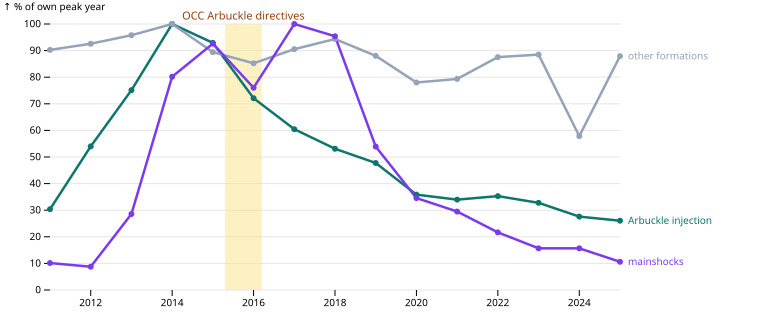

In [28]:
// Arbuckle injection, injection into everything else, and mainshocks, each as % of its own peak year.
const mainsByYear = Object.fromEntries(kinds.toRecords().map((r) => [r.year, r.mainshocks]));
const iy = injYear.toRecords();
const pk = (k: string) => Math.max(...iy.map((d) => d[k]));
const peakM = Math.max(...iy.map((d) => mainsByYear[d.year]));
const timing = iy.flatMap((d) => [
  { year: d.year, share: d.arbuckle_mbbl / pk("arbuckle_mbbl"), series: "Arbuckle injection" },
  { year: d.year, share: d.other_mbbl / pk("other_mbbl"), series: "other formations" },
  { year: d.year, share: mainsByYear[d.year] / peakM, series: "mainshocks" },
]);
Plot.plot({
  document, width: 760, height: 320, marginLeft: 50, marginRight: 140, marginTop: 24,
  x: { label: null, tickFormat: "d" },
  y: { grid: true, percent: true, label: "% of own peak year", domain: [0, 100] },
  color: { domain: ["Arbuckle injection", "other formations", "mainshocks"], range: ["#0f766e", "#94a3b8", "#7c3aed"] },
  marks: [
    Plot.rectY([{ x1: 2015.3, x2: 2016.2 }], { x1: "x1", x2: "x2", y1: 0, y2: 1, fill: "#fde68a", fillOpacity: 0.5 }),
    Plot.text(["OCC Arbuckle directives"], { x: 2015.75, y: 1, dy: -8, fill: "#92400e", fontSize: 11 }),
    Plot.line(timing, { x: "year", y: "share", stroke: "series", strokeWidth: 2.5 }),
    Plot.dot(timing, { x: "year", y: "share", fill: "series", r: 3 }),
    Plot.text(timing.filter((d) => d.year === 2025), { x: "year", y: "share", text: "series", fill: "series", textAnchor: "start", dx: 8 }),
  ],
})

In [29]:
// Same comparison by place: north of 36.5° N (the Kansas-border cluster in section 5) and south of it.
const side = (lat: number) => (lat >= 36.5 ? "north" : "south");
const arbBySide = injOk.filter(pl.col("arbuckle")).withColumns(pl.col("lat").gtEq(36.5).alias("north"))
  .groupBy(["year", "north"]).agg(pl.col("barrels").sum().div(1e6).alias("mbbl")).toRecords();
const placeRows = [2013, 2014, 2015, 2016, 2017, 2018, 2019, 2021, 2023, 2025].map((year) => ({
  year,
  north_arbuckle_mbbl: arbBySide.find((d) => d.year === year && d.north)?.mbbl ?? 0,
  north_mainshocks: mains.filter((d) => d.year === year && side(d.lat) === "north").length,
  south_arbuckle_mbbl: arbBySide.find((d) => d.year === year && !d.north)?.mbbl ?? 0,
  south_mainshocks: mains.filter((d) => d.year === year && side(d.lat) === "south").length,
}));
md(pl.DataFrame(placeRows))

| year | north_arbuckle_mbbl | north_mainshocks | south_arbuckle_mbbl | south_mainshocks |
| --- | --- | --- | --- | --- |
| 2013 | 409 | 13 | 214 | 49 |
| 2014 | 498 | 69 | 332 | 105 |
| 2015 | 479 | 82 | 292 | 119 |
| 2016 | 347 | 63 | 251 | 102 |
| 2017 | 276 | 78 | 225 | 139 |
| 2018 | 221 | 69 | 219 | 138 |
| 2019 | 187 | 32 | 209 | 85 |
| 2021 | 119 | 16 | 163 | 48 |
| 2023 | 105 | 6 | 167 | 28 |
| 2025 | 78 | 5 | 139 | 18 |

In [30]:
// Wells with a location reporting non-Arbuckle volumes, by year: checks the 2024 dip.
md(injOk.filter(pl.col("arbuckle").not()).groupBy("year").agg(pl.col("api").nUnique().alias("located_wells"), pl.col("barrels").sum().div(1e6).alias("mbbl")).sort("year").filter(pl.col("year").gtEq(2020)))

| year | located_wells | mbbl |
| --- | --- | --- |
| 2020 | 6,972 | 1,387 |
| 2021 | 6,827 | 1,410 |
| 2022 | 6,867 | 1,556 |
| 2023 | 6,761 | 1,573 |
| 2024 | 5,030 | 1,028 |
| 2025 | 6,407 | 1,563 |

**Finding.** Timing and place line up with Arbuckle injection, and not with injection in general.

- Arbuckle volumes in the area tripled from 2011 to 2014 (252 to 829 million barrels), then fell every year to 216 million in 2025 (−74%). Injection into other formations stayed at 1.4–1.7 billion barrels most years, with no trend; quakes did not follow it.
- Mainshocks rose behind the Arbuckle rise and peaked in 2017, three years after Arbuckle volumes peaked (2014). They have fallen with them since 2019, and a little faster.
- **By place, 2015 to 2025:** north of 36.5° N, where the cuts were deepest, Arbuckle fell 84% (479 to 78 million barrels) and mainshocks 94% (82 to 5). South of it, Arbuckle fell 52% (292 to 139) and mainshocks 85% (119 to 18). North's share of quakes shrank as its injection did (section 5).

**What this does not show:** mechanism. This notebook shows coincidence in time and place. The physical case, that pressure from Arbuckle disposal spreads to basement faults with a delay, is made elsewhere, not tested here: Keranen et al. 2014, [*Science* 345:448](https://doi.org/10.1126/science.1255802); Langenbruch & Zoback 2016, [*Science Advances* 2:e1601542](https://pmc.ncbi.nlm.nih.gov/articles/PMC5262442/).

Open: the 2024 dip in other-formation volume (1.03 billion) is a reporting gap: about 1,700 fewer wells in the 2024 file have a location (5,030, against 6,400–6,900 in the years around it). 2024 Arbuckle may be slightly low for the same reason.